# Paper figures — *Cosmic string GW backgrounds at LISA: II* ([arXiv:2607.15219](https://arxiv.org/abs/2607.15219))

This notebook makes every figure and Table II of the paper with `gwbf_foregrounds`, **from the
saved results in `results/`**, in the layout of the paper. Run it from the `examples/` folder
(or the repository root) after `pip install -e ".[all]"`.

| Paper | Here | Needs |
|---|---|---|
| Table II | §1 | precision summaries, Fisher file, MCMC precision |
| Fig. 1 | §2 | trained posterior (downloaded), MCMC chain at $G\mu=10^{-14}$ |
| Fig. 2 | §3 | trained posterior |
| Fig. 3 | §4 | precision summaries |
| Fig. 4 | §5 | precision summary, MCMC precision, Fisher file |
| Fig. 5 | §6 | trained posterior, MCMC chains at $10^{-13}$, $10^{-12}$ |

**Data used.** SBI precision: the 20-realisation scans of the analysis. MCMC precision: `results/mcmc_precision_paper.npz`. Fisher: classic Fisher (`fisher_*95_intervals.npz`, no priors).

Expensive inputs can be regenerated in §8 (off by default).

In [1]:
%matplotlib inline
import os, warnings
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

import gwbf_foregrounds as gf
from gwbf_foregrounds import FULL, NOFG, data, posterior, reconstruct, scan, summary, mcmc
from gwbf_foregrounds.plotting import precision as P
from gwbf_foregrounds.plotting.spectra import plot_reconstruction, plot_noise_and_pls
from gwbf_foregrounds.plotting.corner import plot_mcmc_vs_sbi

ROOT = Path.cwd().parent if Path.cwd().name == "examples" else Path.cwd()
RES = ROOT / "results"          # saved inputs
OUT = ROOT / "figures"          # figures are written here
OUT.mkdir(exist_ok=True)

# Trained posteriors: None = download from the GitHub release on first use (~230 MB each),
# or a folder containing posterior_full.pkl / posterior_gbexb.pkl / posterior_nofg.pkl
POSTERIOR_DIR = None

def load_post(model):
    m = gf.get_model(model)
    src = os.path.join(POSTERIOR_DIR, m.posterior_file) if POSTERIOR_DIR else m.name
    return posterior.load_posterior(src, m.param_names)

S = lambda name: RES / name
print("results:", RES, "\nfigures:", OUT)

results: /home/zaldivar/Documents/Androniki/Github2/GWBackFinder-foregrounds/results 
figures: /home/zaldivar/Documents/Androniki/Github2/GWBackFinder-foregrounds/figures


## 1. Table II — reconstruction precision δGμ [%]

δGμ = 100 (Gμ_hi − Gμ_lo)/Gμ_inj for the 95% HDI. SBI: mean over 20 noise realisations.

In [2]:
mc = np.load(S("mcmc_precision_paper.npz"))   # MCMC precision
MCMC = (mc["logGmu_inj"], mc["precision"])
rows = summary.table_ii(S("sbi_fg_summary_with_errors.npz"), S("sbi_nofg_summary_with_errors.npz"),
                        mcmc=MCMC, fisher=S("fisher_95_intervals.npz"))
print(summary.format_table_ii(rows))

 Gmu_inj |       SBI      MCMC     Fisher | SBI no fg
-----------------------------------------------------
   1e-16 |    725.47    570.12   1.57e+05 |     18.71
   1e-15 |    229.49    200.12     223.55 |      8.56
   1e-14 |     91.47     88.23     108.03 |      6.03
   1e-13 |     46.88     52.11      58.90 |      3.22
   1e-12 |     22.06     22.10      26.92 |      2.30
   1e-11 |     11.36     11.30      13.46 |      1.91
   1e-10 |      7.72      7.26       8.28 |      2.52


In [3]:
# Fisher: classic Fisher from fisher_95_intervals.npz (used here) vs the Fisher column of paper v2
FISHER_PAPER = {-16: 1.85e5, -15: 183.78, -14: 68.73, -13: 41.90, -12: 18.81, -11: 7.99, -10: 4.02}
print(f"{'Gmu':>6} | {'Fisher':>9} {'paper v2':>9}")
for r in rows:
    print(f"1e{r['logGmu']:<4} | {r['fisher']:9.4g} {FISHER_PAPER[r['logGmu']]:9.4g}")

   Gmu |    Fisher  paper v2
1e-16  |  1.57e+05  1.85e+05
1e-15  |     223.6     183.8
1e-14  |       108     68.73
1e-13  |      58.9      41.9
1e-12  |     26.92     18.81
1e-11  |     13.46      7.99
1e-10  |     8.283      4.02


In [4]:
print(summary.format_table_ii(rows, latex=True))   # LaTeX version

\begin{tabular}{c|ccc|c}
$G\mu_{\rm inj}$ & SBI & MCMC & Fisher & SBI (no fg) \\ \hline
$10^{-16}$ & 725.47 & 570.12 & 1.57e+05 & 18.71 \\
$10^{-15}$ & 229.49 & 200.12 & 223.55 & 8.56 \\
$10^{-14}$ & 91.47 & 88.23 & 108.03 & 6.03 \\
$10^{-13}$ & 46.88 & 52.11 & 58.90 & 3.22 \\
$10^{-12}$ & 22.06 & 22.10 & 26.92 & 2.30 \\
$10^{-11}$ & 11.36 & 11.30 & 13.46 & 1.91 \\
$10^{-10}$ & 7.72 & 7.26 & 8.28 & 2.52 \\
\end{tabular}


## 2. Fig. 1 — SBI vs MCMC posteriors at Gμ = 10⁻¹⁴

Same mock dataset for both methods (seed 42). A_p and A_acc are inferred but not shown.
log₁₀ A_EMRI is shown at the 3 mHz reference (fiducial −11.34, Table I): the network's relative
amplitude + (−11.34).

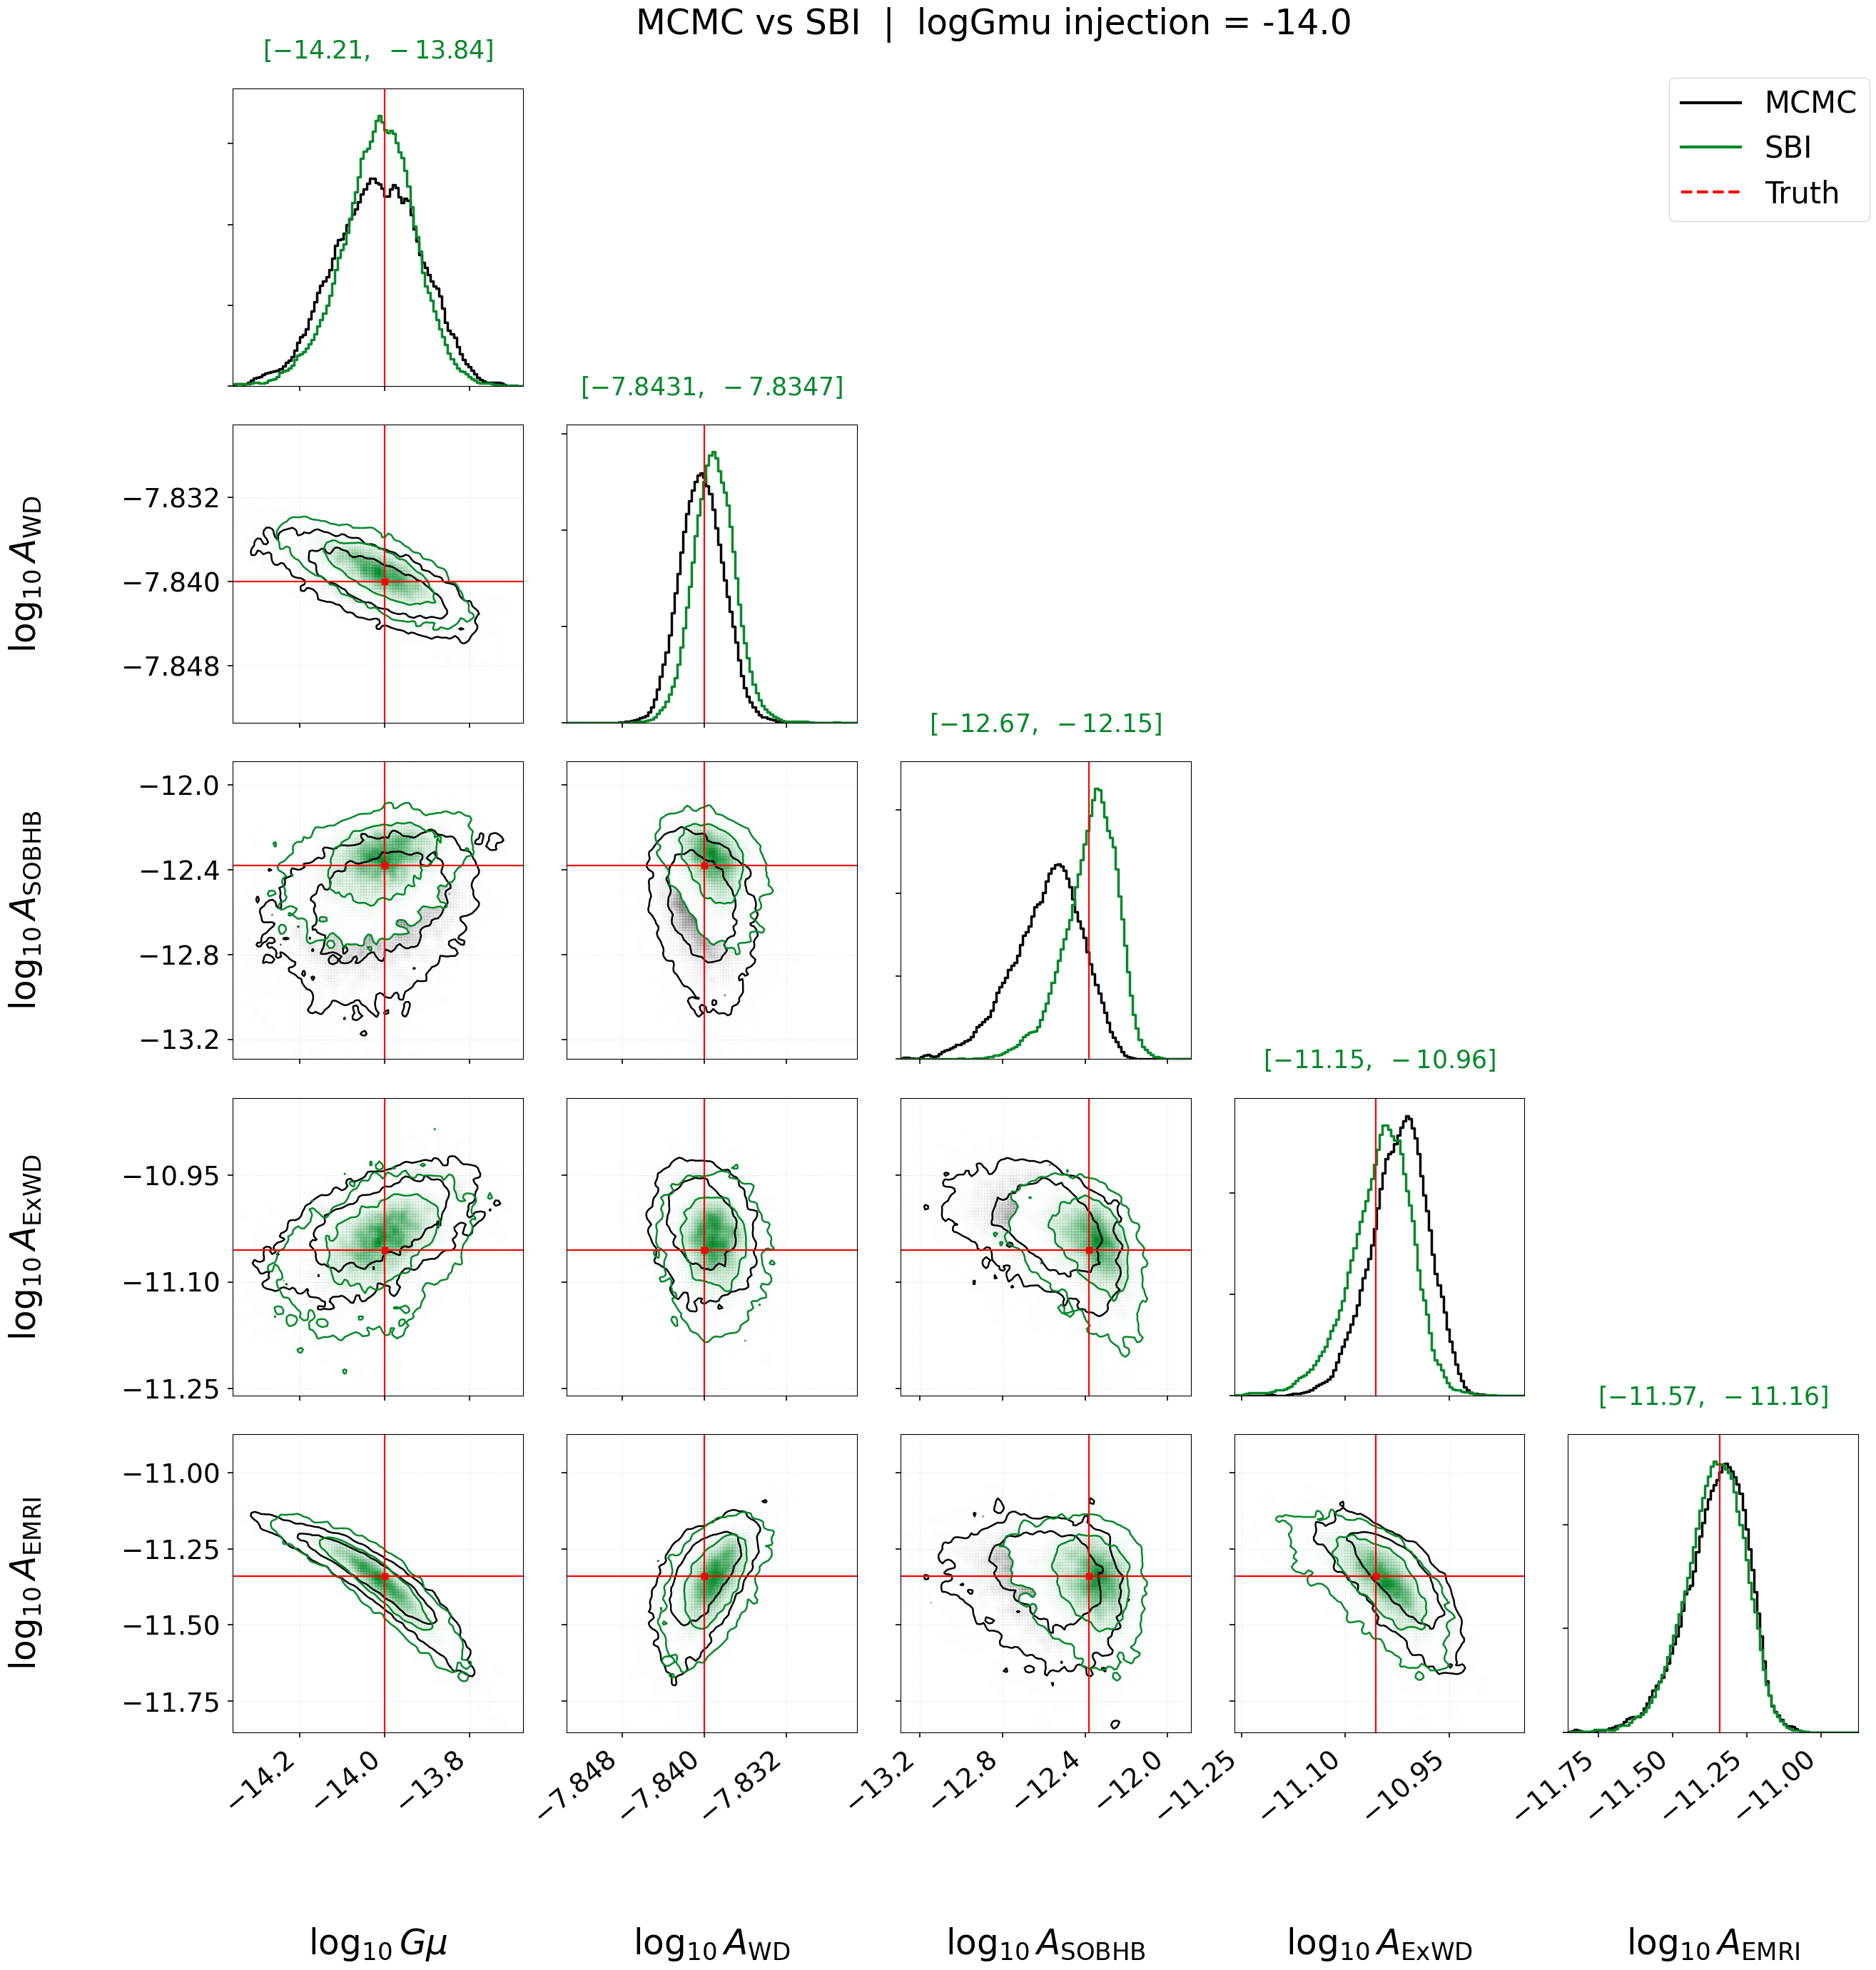

In [5]:
post_full = load_post("full")
EMRI_OFFSET = {"logA_EMRI": -11.34}
SHOW = ["logGmu", "logA_Gal", "logA_ExB", "logA_ExWB", "logA_EMRI"]

def corner_at(tag, title):
    ds = data.Dataset.load(S(f"dataset_full_{tag}_seed42.npz"))
    chain, names, truth = mcmc.load_chain(S(f"mcmc_{tag}_thin50.npz"))
    s_sbi = posterior.sample(post_full, ds, n=10_000, seed=0)
    # axis ranges as in the paper: mean +- 4 std; for A_SOBHB taken from the MCMC chain
    j = names.index("logA_ExB")
    exb = (chain[:, j].mean() - 4 * chain[:, j].std(), chain[:, j].mean() + 4 * chain[:, j].std())
    fig = plot_mcmc_vs_sbi(chain, s_sbi, names, truth, keep=SHOW, offsets=EMRI_OFFSET, title=title,
                           limits={"logA_ExB": exb}, out=OUT / f"fig_corner_{tag}.pdf")
    return fig, ds, s_sbi

fig1, ds14, sbi14 = corner_at("logGmu_m14p0", "MCMC vs SBI  |  logGmu injection = -14.0")

## 3. Fig. 2 — reconstructed spectra at Gμ = 10⁻¹⁴

Posterior median (solid), 95% band, injected (dashed); MBHB fixed; AA noise.

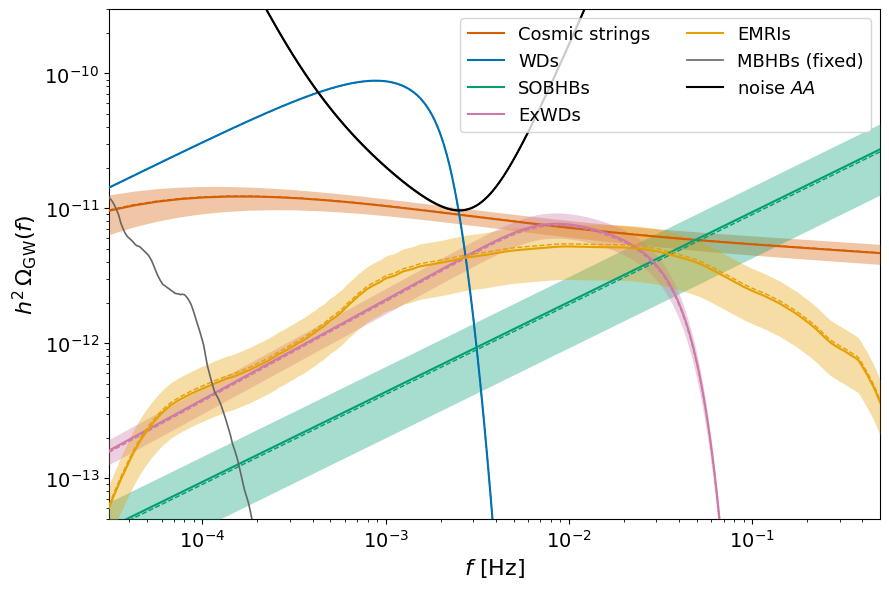

In [6]:
rec14 = reconstruct.reconstruct(sbi14, FULL, ds14.f_obs, truth=ds14.params, max_samples=1000)
fig2 = plot_reconstruction(rec14, show_noise=True, ylim=(5e-14, 3e-10), out=OUT / "fig2_reconstruction.pdf")

## 4. Fig. 3 — precision vs Gμ: foreground budgets (upper) and amplitudes ±1σ (lower)

Error bars: standard deviation over 20 realisations. Red arrows: bars beyond the plot range.

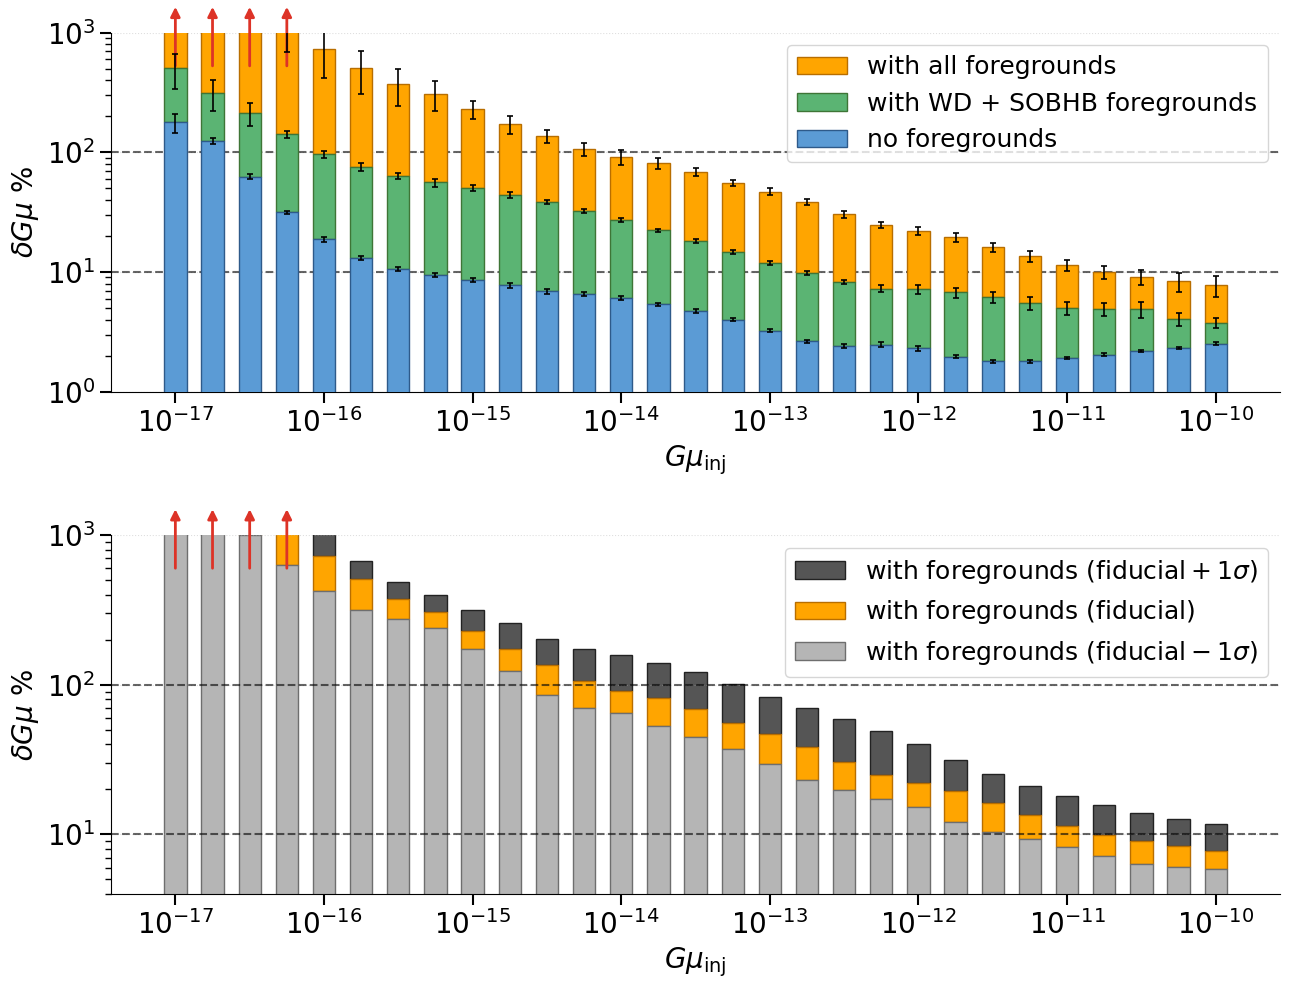

In [7]:
fig3 = P.plot_paper_fig3(S("sbi_nofg_summary_with_errors.npz"), S("sbi_gbexb_summary_with_errors.npz"),
                         S("sbi_fg_summary_with_errors.npz"), S("sbi_lowfg_summary_with_errors.npz"),
                         S("sbi_highfg_summary_with_errors.npz"), out=OUT / "fig3_precision.pdf")

## 5. Fig. 4 — SBI vs MCMC vs Fisher

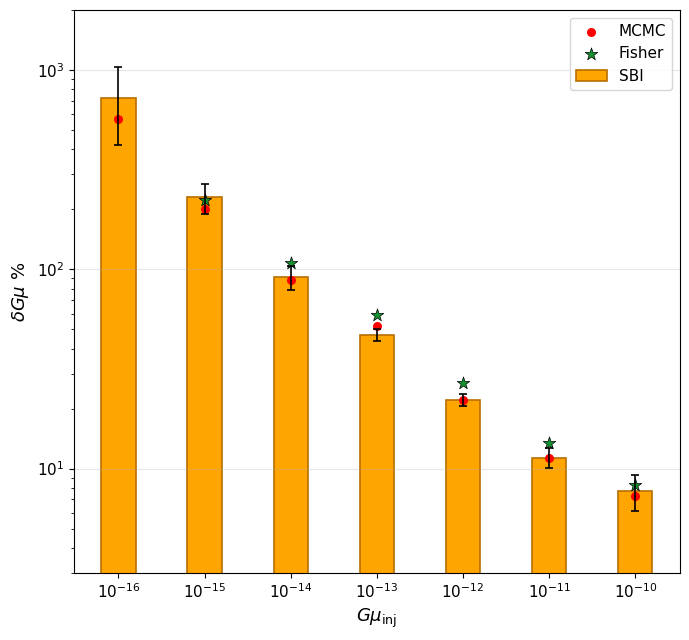

In [8]:
fig4 = P.plot_paper_fig4(S("sbi_fg_summary_with_errors.npz"), mcmc=MCMC,
                         fisher=S("fisher_95_intervals.npz"), out=OUT / "fig4_validation.pdf")

## 6. Fig. 5 — SBI vs MCMC at Gμ = 10⁻¹³ and 10⁻¹²

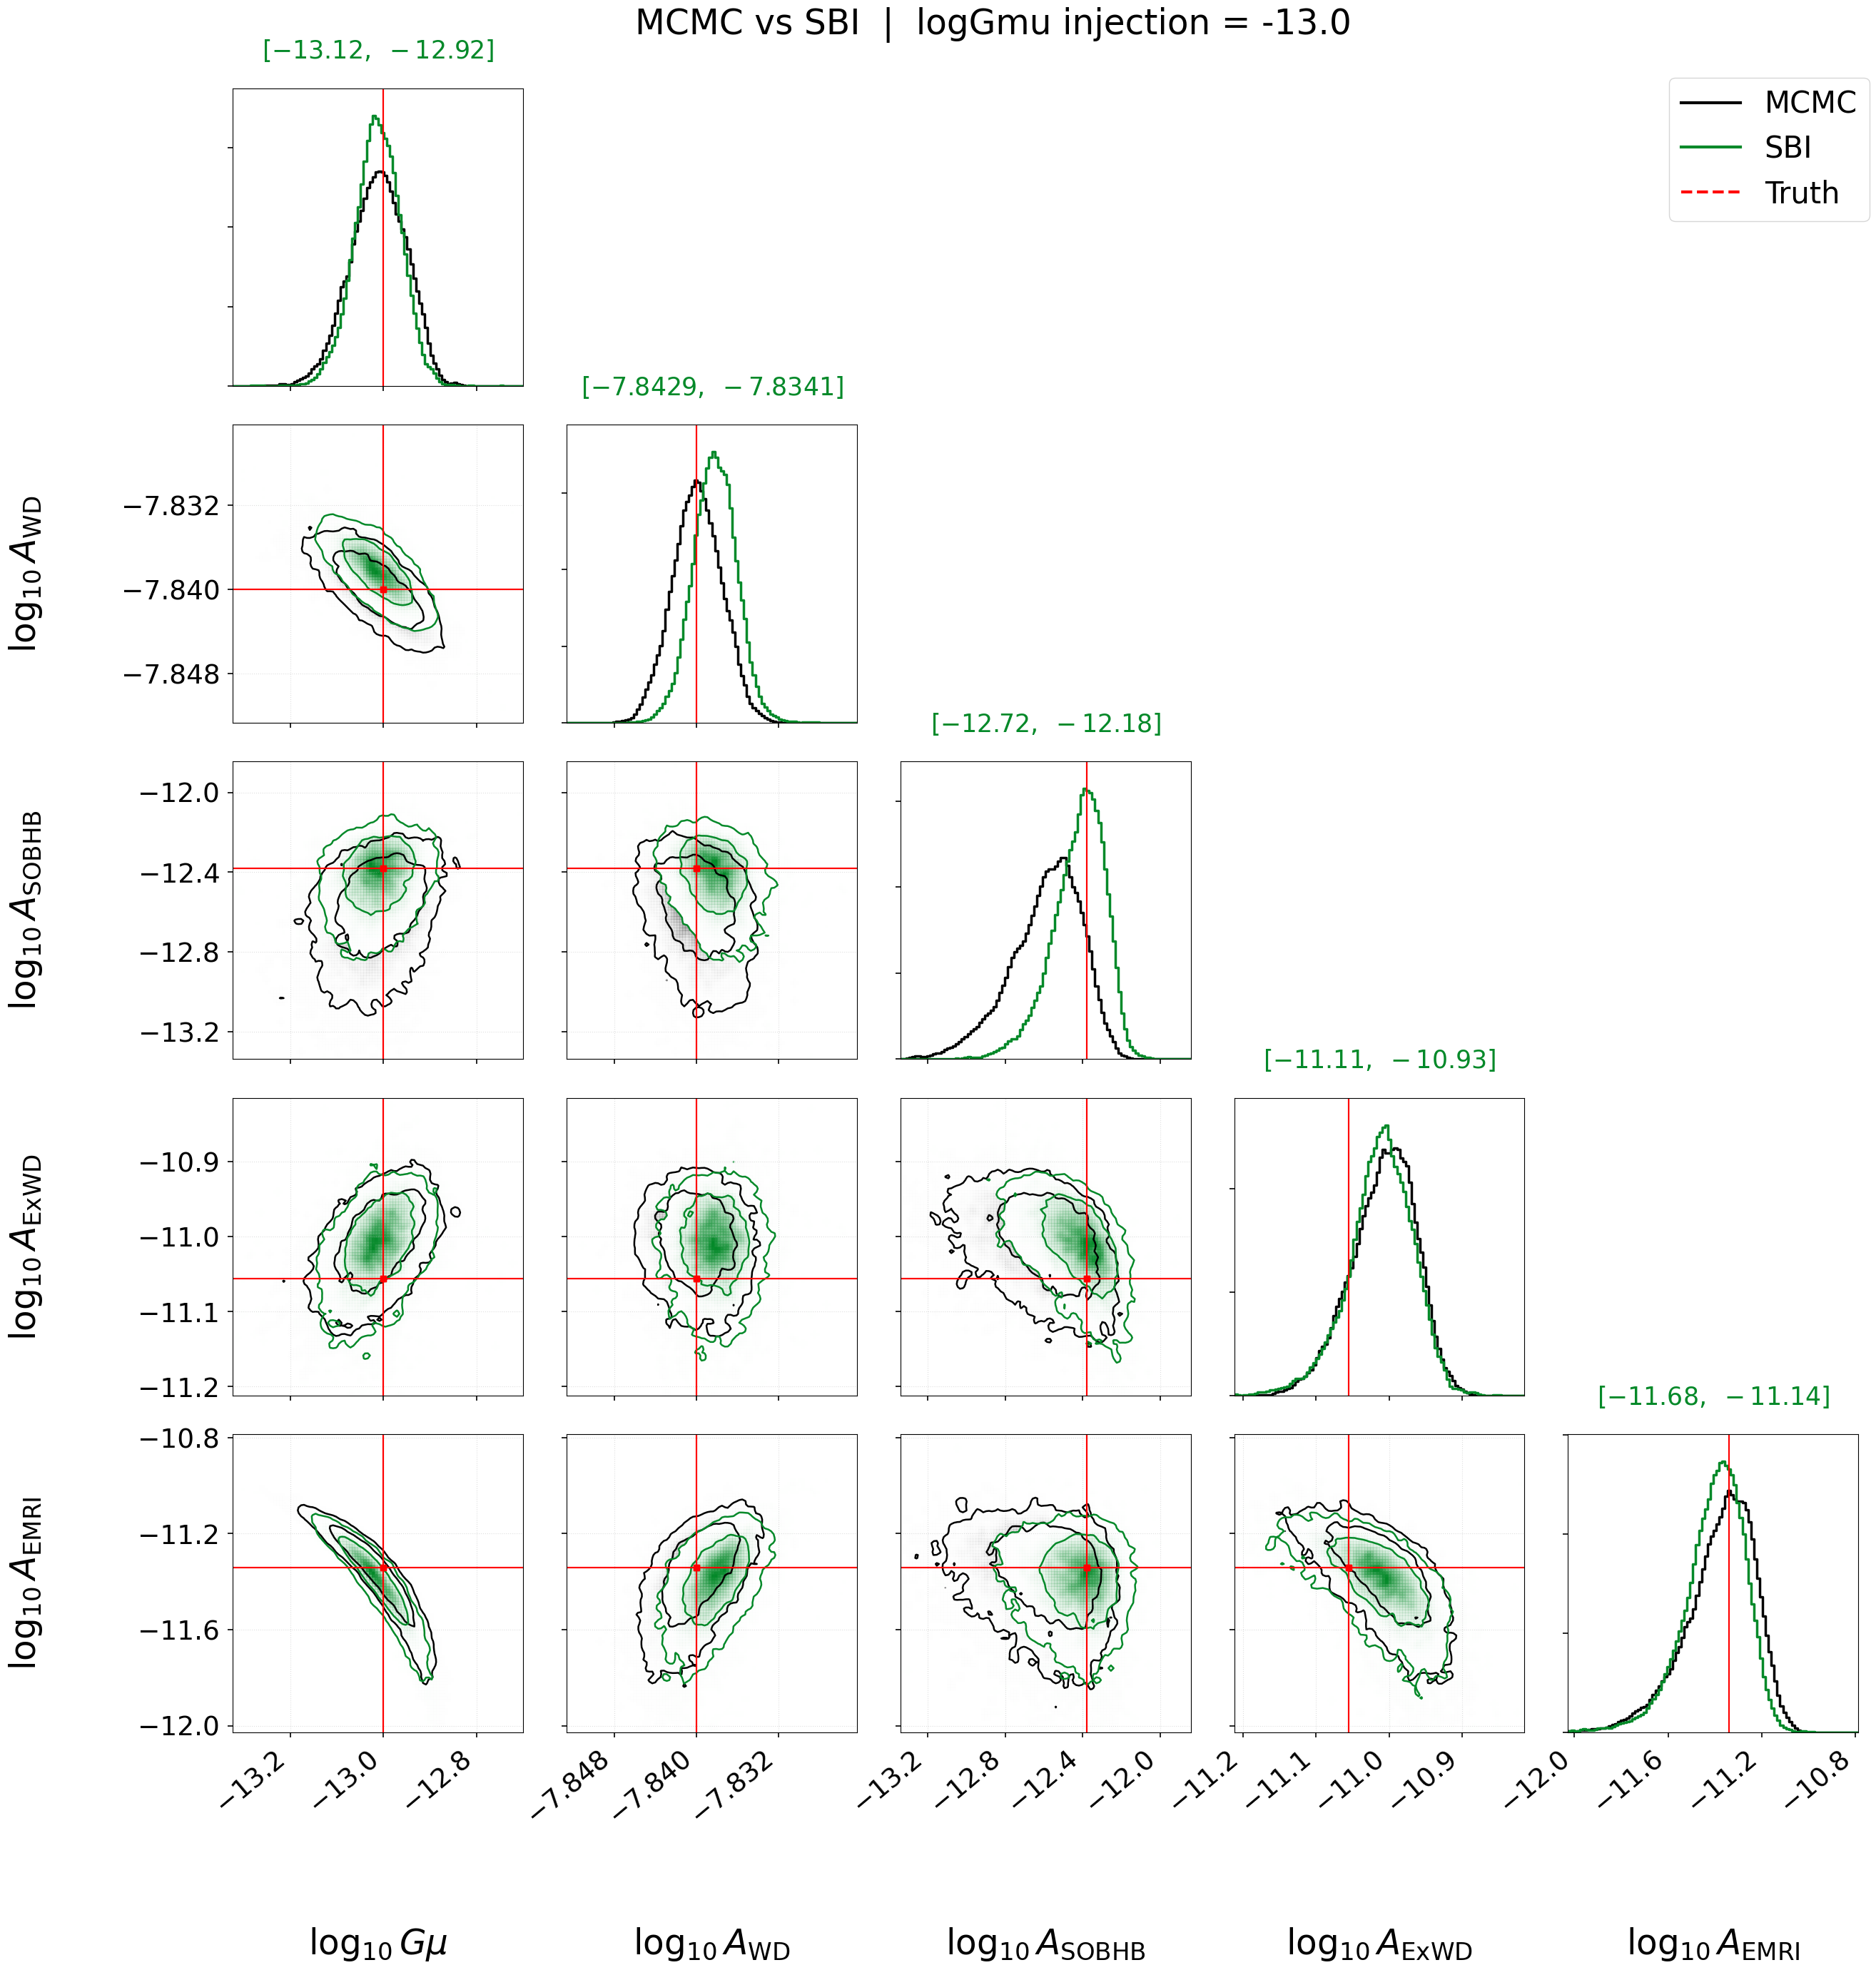

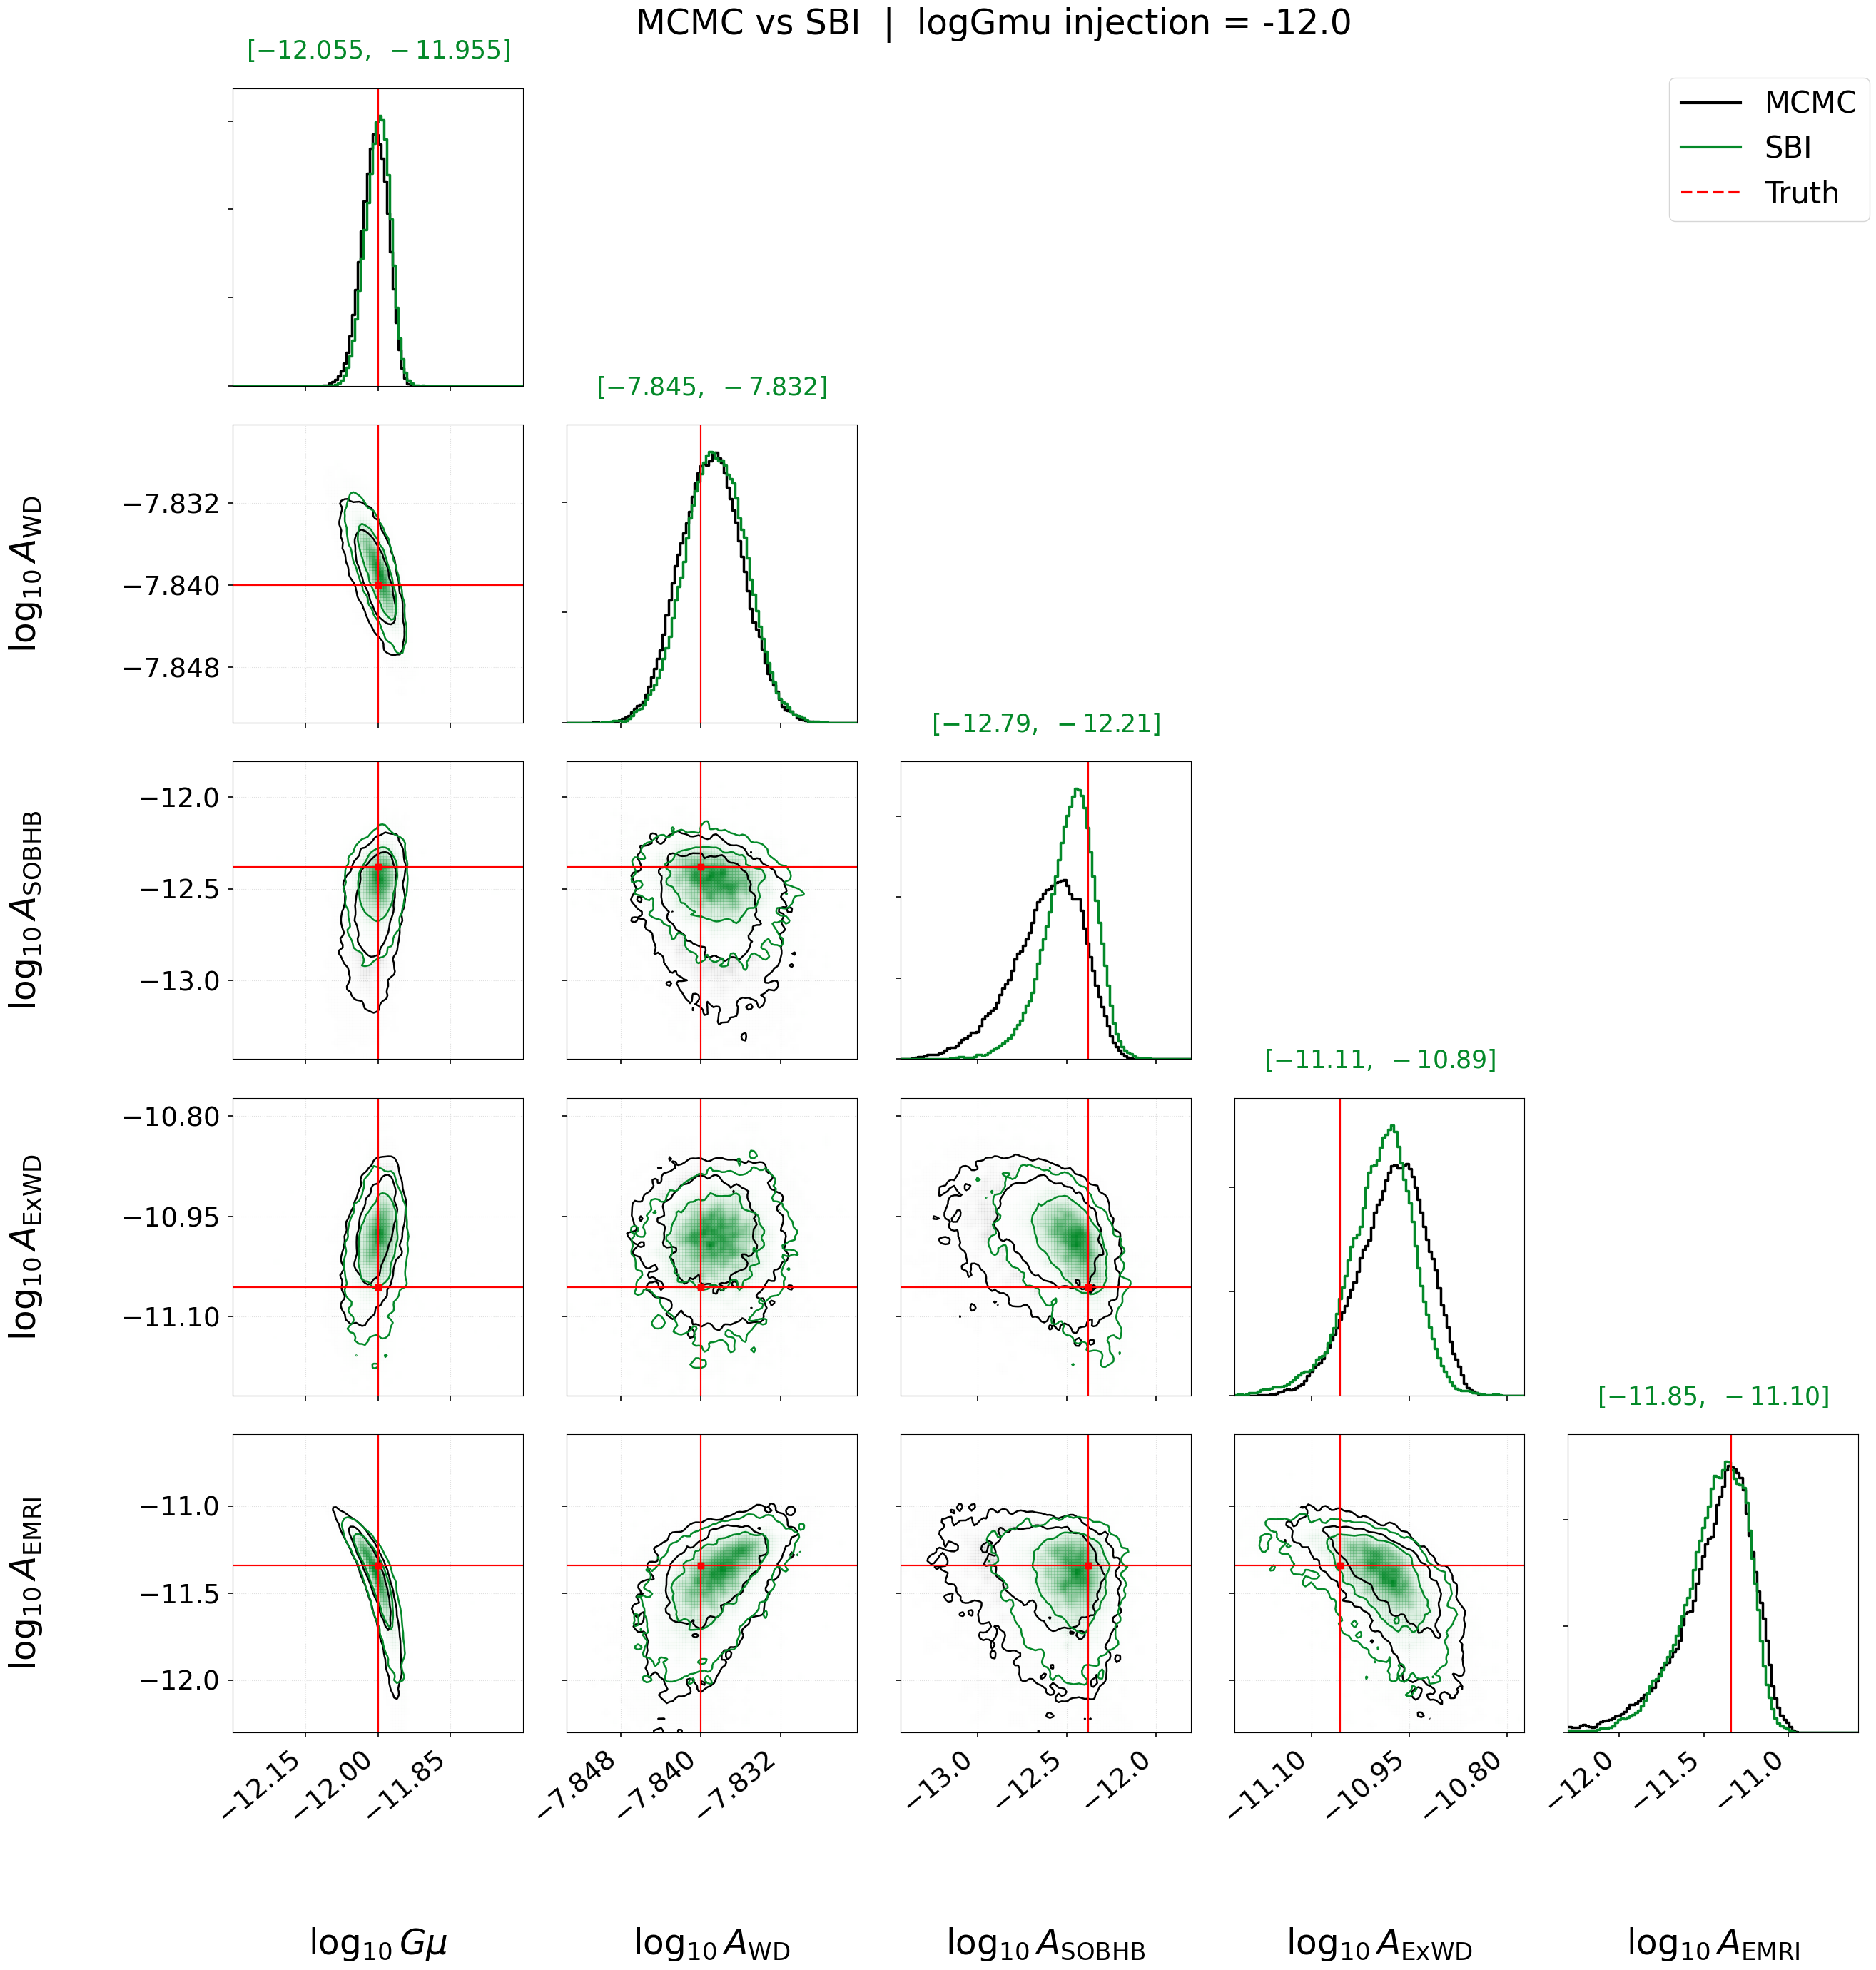

In [9]:
fig5a, _, _ = corner_at("logGmu_m13p0", "MCMC vs SBI  |  logGmu injection = -13.0")
fig5b, _, _ = corner_at("logGmu_m12p0", "MCMC vs SBI  |  logGmu injection = -12.0")

## Extra figures (not in the paper)

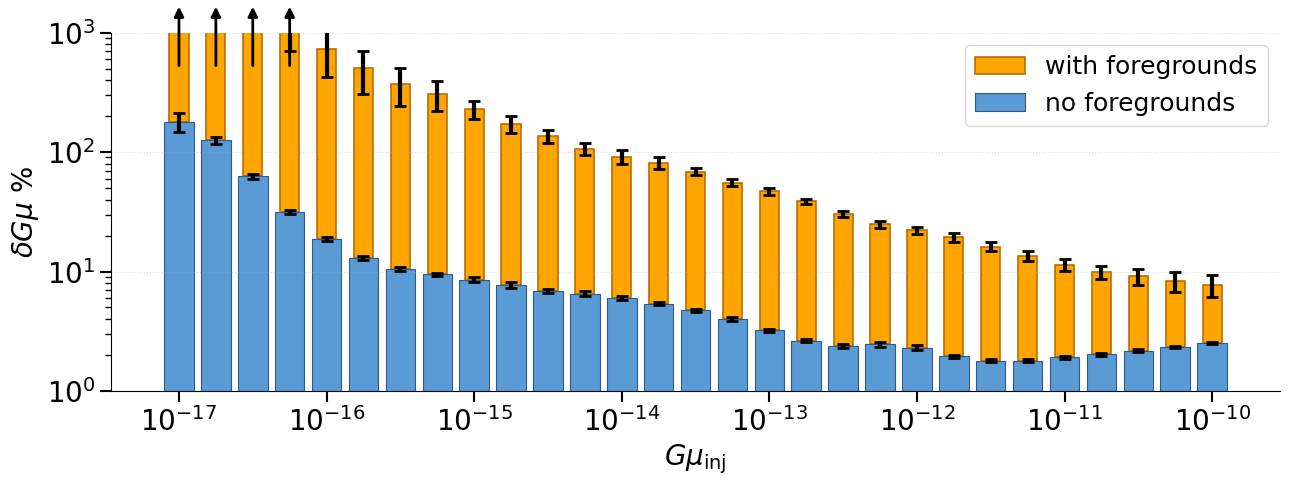

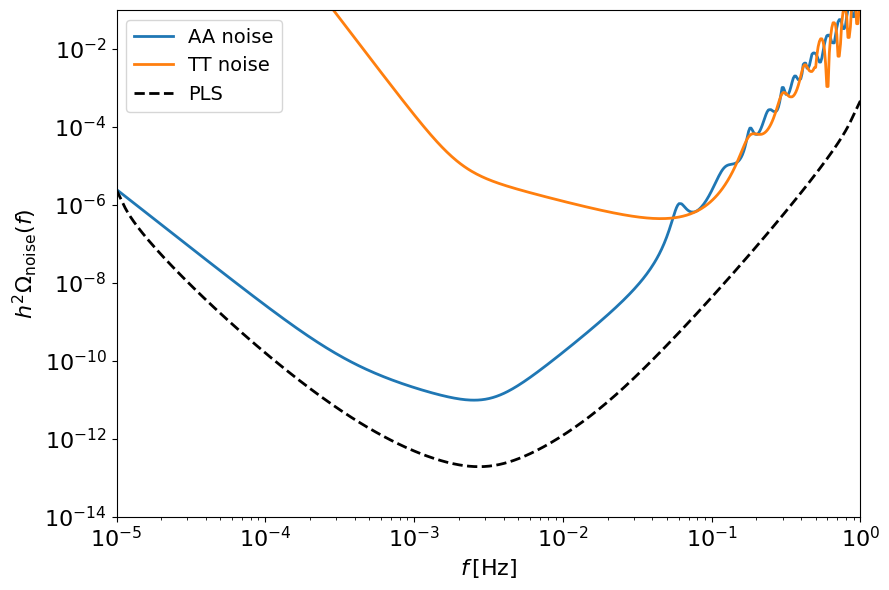

In [10]:
P.plot_fg_vs_nofg(S("sbi_fg_summary_with_errors.npz"), S("sbi_nofg_summary_with_errors.npz"),
                  out=OUT / "sbi_precision_fg_vs_nofg.pdf")
plot_noise_and_pls(out=OUT / "lisa_noise_pls_AA_TT.pdf");

## 7. Regenerating the inputs (slow — off by default)

* SBI precision scans: hours per case.  * Fisher: minutes.  * MCMC: hours per injection.

In [11]:
RUN_SCANS, RUN_FISHER, RUN_MCMC = False, False, False

if RUN_SCANS:
    for model, sign, name in (("full", 0, "sbi_fg"), ("full", -1, "sbi_lowfg"), ("full", 1, "sbi_highfg"),
                              ("nofg", 0, "sbi_nofg"), ("gbexb", 0, "sbi_gbexb")):
        scan.run_sbi_scan(model, posterior=load_post(model), fg_sign=sign, output_dir=RES, summary_name=name)
if RUN_FISHER:
    from gwbf_foregrounds import fisher
    fisher.run_fisher("full", output_dir=RES); fisher.run_fisher("nofg", output_dir=RES)
if RUN_MCMC:
    for lg in (-16, -15, -14, -13, -12, -11, -10):
        ds = data.simulate("full", logGmu=lg, seed=42)
        mcmc.run_mcmc(ds, output_file=RES / f"mcmc_{data.tag_from_logGmu(lg)}.npz")